In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
import os
import glob
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split, cross_val_score,GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import make_classification
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

pd.set_option('display.max_rows', 500)
pd.set_option('display.max_columns', 500)
pd.set_option('display.width', 1000)
warnings.filterwarnings('ignore')

# Reading adae

In [2]:
adae = pd.read_csv("adae_463.csv")

In [3]:
adae = adae[['SUBJID','AESOC','AESTDYI','AEENDYI']]


In [4]:
# Reading adsl

In [5]:
adsl = pd.read_csv("adsl_463.csv")

In [6]:
adsl = adsl[['SUBJID', 'DTHDYX', 'PFSDYCR', 'PFSCR','DIAGMONS',  'B_ECOG', 'DIAGTYPE']]


# Merging adae and adsl

In [7]:
df = pd.merge(adae, adsl, on='SUBJID', how='inner')

In [8]:
df.head()

,SUBJID,AESOC,AESTDYI,AEENDYI,DTHDYX,PFSDYCR,PFSCR,DIAGMONS,B_ECOG,DIAGTYPE
0,1,SKIN AND SUBCUTANEOUS TISSUE DISORDERS,29.0,43.0,218.0,84.0,1.0,54.983607,Symptoms but ambulatory,Colon
1,1,SKIN AND SUBCUTANEOUS TISSUE DISORDERS,57.0,142.0,218.0,84.0,1.0,54.983607,Symptoms but ambulatory,Colon
2,1,SKIN AND SUBCUTANEOUS TISSUE DISORDERS,158.0,172.0,218.0,84.0,1.0,54.983607,Symptoms but ambulatory,Colon
3,2,SKIN AND SUBCUTANEOUS TISSUE DISORDERS,NaN,NaN,231.0,57.0,1.0,24.983607,Symptoms but ambulatory,Colon
4,4,SKIN AND SUBCUTANEOUS TISSUE DISORDERS,NaN,NaN,581.0,581.0,1.0,19.409836,Fully active,Colon


In [9]:
result_df = pd.get_dummies(df, drop_first=True, prefix_sep='_').dropna().astype(int)



In [10]:
result_df

,SUBJID,AESTDYI,AEENDYI,DTHDYX,PFSDYCR,PFSCR,DIAGMONS,AESOC_INFECTIONS AND INFESTATIONS,"AESOC_INJURY, POISONING AND PROCEDURAL COMPLICATIONS",AESOC_SKIN AND SUBCUTANEOUS TISSUE DISORDERS,AESOC_VASCULAR DISORDERS,B_ECOG_In bed less than 50% of the time,B_ECOG_Symptoms but ambulatory,DIAGTYPE_Rectal
0,1,29,43,218,84,1,54,0,0,1,0,0,1,0
1,1,57,142,218,84,1,54,0,0,1,0,0,1,0
2,1,158,172,218,84,1,54,0,0,1,0,0,1,0
5,6,15,29,286,112,1,30,0,0,1,0,0,0,1
6,6,15,112,286,112,1,30,0,0,1,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1028,456,7,34,32,32,1,19,0,0,1,0,0,0,0
1029,456,7,34,32,32,1,19,0,0,1,0,0,0,0
1030,456,22,33,32,32,1,19,0,0,0,0,0,0,0
1033,461,8,69,175,53,1,8,0,0,1,0,0,0,1


# Groupby

In [11]:
aesoc_cols = [col for col in result_df.columns if col.startswith('AESOC_')]

In [12]:
grouped = result_df.groupby('SUBJID')

In [13]:
aesoc_counts = grouped[aesoc_cols].sum().reset_index() #sum of the values in the aesoc_cols for each subject (as grouped by 'SUBJID').

In [14]:
columns_to_convert = [col for col in aesoc_counts.columns if col != 'SUBJID'] # Selecting all other columns except subjid
aesoc_counts[columns_to_convert] = (aesoc_counts[columns_to_convert] > 0).astype(int)  # if greater than 0, true, 1

In [15]:
aesoc_counts

,SUBJID,AESOC_INFECTIONS AND INFESTATIONS,"AESOC_INJURY, POISONING AND PROCEDURAL COMPLICATIONS",AESOC_SKIN AND SUBCUTANEOUS TISSUE DISORDERS,AESOC_VASCULAR DISORDERS
0,1,0,0,1,0
1,6,0,0,1,0
2,10,0,0,1,0
3,13,0,0,1,0
4,16,0,0,1,0
5,20,0,0,1,0
6,21,0,1,1,0
7,27,0,0,1,0
8,34,0,0,1,0
9,38,0,0,1,0


# Dropping inconsistent columns

In [16]:
# For each non-AESOC column, drop it if it varies within the same SUBJID group
def drop_inconsistent_columns(group):
    # Keeping only columns that are consistent across all rows in each group
    consistent_columns = [col for col in group.columns if group[col].nunique() == 1]
    return group[consistent_columns].head(1)  # Retain only one row per group

In [17]:
consistent_features = grouped.apply(drop_inconsistent_columns).reset_index(drop=True)
consistent_features.drop(columns=aesoc_cols ,inplace=True)
result = pd.merge(consistent_features, aesoc_counts, on='SUBJID', how='left')

In [18]:
result.fillna(0, inplace=True)

In [19]:
result.head(10)

,SUBJID,DTHDYX,PFSDYCR,PFSCR,DIAGMONS,B_ECOG_In bed less than 50% of the time,B_ECOG_Symptoms but ambulatory,DIAGTYPE_Rectal,AESTDYI,AEENDYI,AESOC_INFECTIONS AND INFESTATIONS,"AESOC_INJURY, POISONING AND PROCEDURAL COMPLICATIONS",AESOC_SKIN AND SUBCUTANEOUS TISSUE DISORDERS,AESOC_VASCULAR DISORDERS
0,1,218,84,1,54,0,1,0,0.0,0.0,0,0,1,0
1,6,286,112,1,30,0,0,1,0.0,0.0,0,0,1,0
2,10,129,53,1,22,0,1,0,0.0,0.0,0,0,1,0
3,13,230,170,1,76,1,0,1,0.0,0.0,0,0,1,0
4,16,481,162,1,21,0,1,1,0.0,0.0,0,0,1,0
5,20,461,166,1,25,0,0,1,0.0,0.0,0,0,1,0
6,21,291,164,1,29,0,1,1,0.0,0.0,0,1,1,0
7,27,664,228,1,23,0,1,0,0.0,0.0,0,0,1,0
8,34,86,50,1,36,0,1,0,22.0,43.0,0,0,1,0
9,38,189,189,1,33,1,0,0,15.0,142.0,0,0,1,0


In [20]:
result.shape

(150, 14)

In [21]:
result.to_csv('processed_dataframe_segAE_463.csv', index=False)

# XGBoost and RandomForest classifiers 

In [22]:
import pandas as pd
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.multioutput import MultiOutputClassifier
from sklearn.metrics import mean_squared_error
from scipy.stats import uniform, randint

# For reproducibility
import numpy as np
np.random.seed(42)



In [23]:
X = result.drop(columns=aesoc_cols)
y = result[aesoc_cols] # y contains the target labels (the AESOC_* columns), which represent the adverse events.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


#  For hyperparameter tuning

In [24]:
xgb_param_grid = {
    'n_estimators': randint(50, 500),
    'max_depth': randint(3, 10),
    'learning_rate': uniform(0.01, 0.1),
    'subsample': uniform(0.6, 0.9),
    'colsample_bytree': uniform(0.6, 0.9)
}

In [25]:
param_grid={
    'n_estimators': randint(50, 500),
    'max_depth': randint(3, 10),
    'learning_rate': uniform(0.01, 0.1),
    'subsample': uniform(0.6, 0.9),
    'colsample_bytree': uniform(0.6, 0.9)
}

# MultiOutputClassifier XGBoost Hyperparameter Grid

In [26]:
param_grid = {
    'estimator__n_estimators': randint(50, 500),
    'estimator__max_depth': randint(3, 10),
    'estimator__learning_rate': uniform(0.01, 0.1),
    'estimator__subsample': uniform(0.6, 0.9),
    'estimator__colsample_bytree': uniform(0.6, 0.9),
}

# Hyperparameters for the RandomForestClassifier in MultiOutputClassifier

In [27]:
rf_param_dist = {
    'estimator__n_estimators': randint(100, 500),  
    'estimator__max_depth': randint(10, 50),  
    'estimator__min_samples_split': randint(2, 20), 
    'estimator__min_samples_leaf': randint(1, 10),  
    'estimator__bootstrap': [True, False]  
}

# XGB Classifier

In [28]:
base_model = XGBClassifier(use_label_encoder=False, eval_metric='logloss')
multi_output_model = MultiOutputClassifier(base_model)

# Finding the best combination of hyperparameters for the model

In [29]:
random_search = RandomizedSearchCV(
    estimator=multi_output_model,
    param_distributions=param_grid,
    n_iter=50, 
    cv=3,       
    verbose=2,
    random_state=42,
    n_jobs=-1   
)

In [30]:
random_search.fit(X_train, y_train)
print("Best parameters:", random_search.best_params_)
best_model = random_search.best_estimator_

Fitting 3 folds for each of 50 candidates, totalling 150 fits
Best parameters: {'estimator__colsample_bytree': 0.8805399684804698, 'estimator__learning_rate': 0.06200680211778108, 'estimator__max_depth': 4, 'estimator__n_estimators': 309, 'estimator__subsample': 0.7663690099729743}


In [31]:
y_pred = best_model.predict(X_test)

# Evaluating Model Performance

In [32]:
for i, col in enumerate(y.columns):
    print(f"\nClassification Report for {col}:")
    print(classification_report(y_test.iloc[:, i], y_pred[:, i]))
    print(f"Accuracy for {col}: {accuracy_score(y_test.iloc[:, i], y_pred[:, i])}")


Classification Report for AESOC_INFECTIONS AND INFESTATIONS:
              precision    recall  f1-score   support

           0       0.90      0.96      0.93        27
           1       0.00      0.00      0.00         3

    accuracy                           0.87        30
   macro avg       0.45      0.48      0.46        30
weighted avg       0.81      0.87      0.84        30

Accuracy for AESOC_INFECTIONS AND INFESTATIONS: 0.8666666666666667

Classification Report for AESOC_INJURY, POISONING AND PROCEDURAL COMPLICATIONS:
              precision    recall  f1-score   support

           0       0.97      1.00      0.98        29
           1       0.00      0.00      0.00         1

    accuracy                           0.97        30
   macro avg       0.48      0.50      0.49        30
weighted avg       0.93      0.97      0.95        30

Accuracy for AESOC_INJURY, POISONING AND PROCEDURAL COMPLICATIONS: 0.9666666666666667

Classification Report for AESOC_SKIN AND SUBCUTAN

# Feature Importance

In [33]:
feature_importances = []
for i, estimator in enumerate(best_model.estimators_):
    importance = estimator.feature_importances_
    feature_importances.append(pd.DataFrame({
        'feature': X.columns,
        'importance': importance,
        'target': y.columns[i]
    }))

# Combining feature importances for all target variables
feature_importance_combined = pd.concat(feature_importances, ignore_index=True)

# Calculating average importance across all targets
avg_importance = feature_importance_combined.groupby('feature')['importance'].mean().reset_index()
avg_importance = avg_importance.sort_values('importance', ascending=False)

print("Average feature importance across all target variables:")
print(avg_importance)

Average feature importance across all target variables:
                                   feature  importance
9                                   SUBJID    0.193812
4                                 DIAGMONS    0.184628
8                                  PFSDYCR    0.181280
6                                   DTHDYX    0.148101
3           B_ECOG_Symptoms but ambulatory    0.103335
1                                  AESTDYI    0.092619
0                                  AEENDYI    0.050061
5                          DIAGTYPE_Rectal    0.046165
2  B_ECOG_In bed less than 50% of the time    0.000000
7                                    PFSCR    0.000000


In [34]:
# individul feature importance for each target variable separately
for target in y.columns:
    print(f"\nTop feature importance for {target}:")
    target_importance = feature_importance_combined[feature_importance_combined['target'] == target]
    target_importance = target_importance.sort_values('importance', ascending=False)
    print(target_importance.head(10)) 



Top feature importance for AESOC_INFECTIONS AND INFESTATIONS:
                                   feature  importance                             target
2                                  PFSDYCR    0.267729  AESOC_INFECTIONS AND INFESTATIONS
7                          DIAGTYPE_Rectal    0.184659  AESOC_INFECTIONS AND INFESTATIONS
1                                   DTHDYX    0.184143  AESOC_INFECTIONS AND INFESTATIONS
0                                   SUBJID    0.142710  AESOC_INFECTIONS AND INFESTATIONS
4                                 DIAGMONS    0.114208  AESOC_INFECTIONS AND INFESTATIONS
6           B_ECOG_Symptoms but ambulatory    0.106551  AESOC_INFECTIONS AND INFESTATIONS
3                                    PFSCR    0.000000  AESOC_INFECTIONS AND INFESTATIONS
5  B_ECOG_In bed less than 50% of the time    0.000000  AESOC_INFECTIONS AND INFESTATIONS
8                                  AESTDYI    0.000000  AESOC_INFECTIONS AND INFESTATIONS
9                                  AE

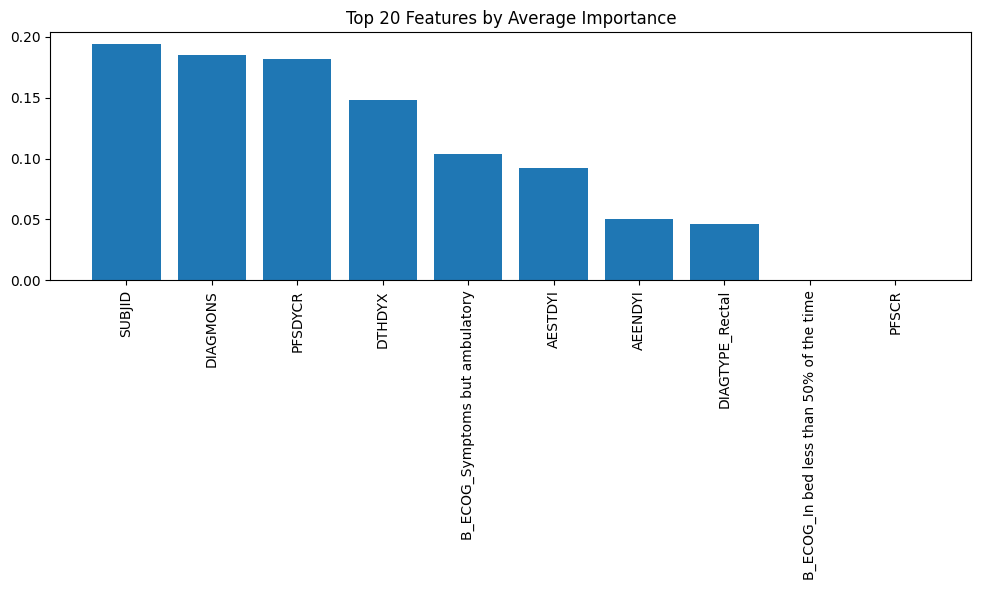

In [35]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.bar(avg_importance['feature'][:20], avg_importance['importance'][:20])
plt.xticks(rotation=90)
plt.title('Top 20 Features by Average Importance')
plt.tight_layout()
plt.show()